# 08 - LSTM for abandonment prediction

- Goal: predict whether a visitor will leave within the next few page views, and combine this with module 1.

- Reproduces: the method of paper Sections 3 and 4.2, Figure 2, Algorithm 1 and Figure 1.

- Needs: notebook 07 (reads data/synthetic_clickstream.csv). Writes results/lstm.csv and results/lstm_thresholds.csv.

- Expected run time: about 9 minutes on a GPU with 5 seeds (measured). A CPU would be slower.


Repeats: 5 seeds (N_SEEDS = 5). The paper does not state a number of repeats for this module.

### The data is SYNTHETIC!! 
(We made this data ourselves in notebook 07. Accuracy values here are not comparable with the paper's numbers. Only the method is replicated.)

## 1. Setup
N_SEEDS is the number of repeats in this notebook. QUICK_TEST = True runs a tiny version to check the code: 3 seeds, 300 sessions and 2 epochs. These saved results come from the real run, with QUICK_TEST = False.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Windows: set before the other imports

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from torch import nn

from utils import (COLOURS, DEVICE, get_metrics, paired_test, predict_mlp, save_results,
                   set_style, show_table, to_tensor, train_mlp)

QUICK_TEST = False  # True: tiny run to check the code, not for results
N_REPEATS = 10  # paper uses 100 (not used here: this notebook repeats with N_SEEDS)
N_SEEDS = 5
EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.001
STEP_SIZE = 3  # sequence length, as in the paper
HORIZONS = [1, 2, 3, 4, 5, 6]
THRESHOLDS = [0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
PAGES = ["product", "administrative", "informational", "cart"]
PREFIX = ""
MAX_SESSIONS = None

if QUICK_TEST:
    N_SEEDS = 3
    EPOCHS = 2
    MAX_SESSIONS = 300
    PREFIX = "quick_"

set_style()
print("Device:", DEVICE)

Device: cuda


## 2. Build the windows
Each page view becomes 5 numbers: 4 columns of 0s and 1s for the page type, plus the time on the page. A window is the last 3 page views, so for each position t from 3 onwards it holds steps t-2 to t.

The prediction horizon, h, is how many page views ahead we look. With remaining as the number of page views left in the session after position t, the label is 1 if remaining is h or less, and 0 otherwise. So at the last page of a session remaining is 0, and every horizon labels that window 1.

In [2]:
clicks = pd.read_csv("data/synthetic_clickstream.csv")
if MAX_SESSIONS:
    clicks = clicks[clicks["session_id"] < MAX_SESSIONS]

def make_windows(data):
    """Return windows (n, 3, 5), remaining page views, and the session of each window."""
    windows, remaining, sessions = [], [], []
    for session_id, group in data.groupby("session_id"):
        one_hot = np.eye(4)[group["page_type"].map(PAGES.index).values]
        steps = np.column_stack([one_hot, group["seconds"].values])
        for t in range(STEP_SIZE - 1, len(steps)):
            windows.append(steps[t - STEP_SIZE + 1: t + 1])
            remaining.append(len(steps) - 1 - t)
            sessions.append(session_id)
    return np.array(windows, dtype=np.float32), np.array(remaining), np.array(sessions)

windows, remaining, session_of = make_windows(clicks)
print("Windows:", windows.shape, "| Sessions:", len(np.unique(session_of)))

Windows: (164809, 3, 5) | Sessions: 9800


We get 164,809 windows from 9,800 sessions.

## 3. Split sessions and balance
We split sessions, not rows, so windows from one session never appear in both train and test. We standardize time on page using train values.

As in the paper, each horizon gets a balanced test set, with equal numbers of positive and negative windows. We also balance the training windows, by undersampling, which means randomly dropping rows of the larger class.

In [3]:
def split_sessions(seed):
    """Random 70/30 split of the sessions. Returns boolean masks over the windows."""
    rng = np.random.default_rng(seed)
    ids = rng.permutation(np.unique(session_of))
    train_ids = ids[: int(0.7 * len(ids))]
    is_train = np.isin(session_of, train_ids)
    return is_train, ~is_train


def scale_time(X_train, X_test):
    """Standardize the time column (index 4) with train statistics."""
    mean = X_train[:, :, 4].mean()
    std = X_train[:, :, 4].std()
    X_train = X_train.copy()
    X_test = X_test.copy()
    X_train[:, :, 4] = (X_train[:, :, 4] - mean) / std
    X_test[:, :, 4] = (X_test[:, :, 4] - mean) / std
    return X_train, X_test


def balance(X, y, seed):
    """Undersample the larger class so both classes have the same size."""
    rng = np.random.default_rng(seed)
    pos = np.where(y == 1)[0]
    neg = np.where(y == 0)[0]
    n = min(len(pos), len(neg))
    keep = np.concatenate([rng.choice(pos, n, replace=False), rng.choice(neg, n, replace=False)])
    keep = rng.permutation(keep)
    return X[keep], y[keep]

## 4. The LSTM
An LSTM (long short-term memory network) is a neural network that reads a sequence step by step and remembers what it saw earlier. As in paper Section 4, ours has one hidden layer with 30 LSTM units and one sigmoid output, which gives a score between 0 and 1. We train it with Adam, learning rate 0.001, and binary cross-entropy loss.

Deviation from the paper: the paper does not state its optimiser, learning rate or number of epochs. These follow our project plan. It also does not say how it balanced the training data.

In [4]:
class LSTMNet(nn.Module):
    """LSTM with 30 units and a sigmoid output on the last step."""

    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=5, hidden_size=30, num_layers=1, batch_first=True)
        self.out = nn.Linear(30, 1)

    def forward(self, x):
        states, _ = self.lstm(x)
        return torch.sigmoid(self.out(states[:, -1])).squeeze(1)


def train_lstm(X, y, seed):
    """Mini-batch training with Adam and binary cross-entropy."""
    torch.manual_seed(seed)
    X_t = to_tensor(X)
    y_t = to_tensor(y)
    model = LSTMNet().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.BCELoss()
    for _ in range(EPOCHS):
        order = torch.randperm(len(X_t), device=DEVICE)
        for start in range(0, len(X_t), BATCH_SIZE):
            batch = order[start: start + BATCH_SIZE]
            optimizer.zero_grad()
            loss = loss_fn(model(X_t[batch]), y_t[batch])
            loss.backward()
            optimizer.step()
    return model


def score_lstm(model, X):
    """Sigmoid scores for the test windows."""
    with torch.no_grad():
        return model(to_tensor(X)).cpu().numpy()

## 5. The three time-delay models
The paper compares the LSTM with three networks that see the last 3 page views flattened into one input of 15 numbers. These are an MLP with 10 hidden neurons (train_mlp from utils.py), an Extreme Learning Machine (ELM) with 75 hidden neurons, whose hidden weights stay random and fixed, and an RBF network with 8 centres, which measures how close each input is to 8 typical points.

In [5]:
def run_elm(X_train, y_train, X_test, seed, hidden=75):
    """ELM: random fixed hidden weights, sigmoid, output weights by least squares."""
    rng = np.random.default_rng(seed)
    weights = rng.normal(size=(X_train.shape[1], hidden))
    bias = rng.normal(size=hidden)
    hidden_train = 1 / (1 + np.exp(-(X_train @ weights + bias)))
    hidden_test = 1 / (1 + np.exp(-(X_test @ weights + bias)))
    beta = np.linalg.pinv(hidden_train) @ y_train
    return (hidden_test @ beta > 0.5).astype(int)


def rbf_features(X, centres, width):
    """Gaussian feature for each centre."""
    dist = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
    return np.exp(-dist / (2 * width ** 2))


def run_rbf(X_train, y_train, X_test, seed, n_centres=8):
    """RBF network: KMeans centres, Gaussian features, then logistic regression."""
    kmeans = KMeans(n_clusters=n_centres, n_init=3, random_state=seed).fit(X_train)
    width = np.mean(np.linalg.norm(X_train - kmeans.cluster_centers_[kmeans.labels_], axis=1))
    model = LogisticRegression(max_iter=1000)
    model.fit(rbf_features(X_train, kmeans.cluster_centers_, width), y_train)
    return model.predict(rbf_features(X_test, kmeans.cluster_centers_, width))

## 6. Run every model at every horizon
All four models use the same seeds and the same test windows, so the t-tests are paired. For the LSTM we also record the true positive rate and precision at each threshold of Figure 2 (right).

In [6]:
start = time.time()
rows, threshold_rows, check_rows = [], [], []
for seed in range(N_SEEDS):
    is_train, is_test = split_sessions(seed)
    for h in HORIZONS:
        labels = (remaining <= h).astype(np.float32)
        X_tr, y_tr = balance(windows[is_train], labels[is_train], seed)
        X_te, y_te = balance(windows[is_test], labels[is_test], seed)
        X_tr, X_te = scale_time(X_tr, X_te)
        flat_tr = X_tr.reshape(len(X_tr), -1)
        flat_te = X_te.reshape(len(X_te), -1)

        # LSTM
        lstm = train_lstm(X_tr, y_tr, seed)
        scores = score_lstm(lstm, X_te)
        check_rows.append({
            "Horizon": h,
            "Train pos (before balancing)": (labels[is_train] == 1).sum(),
            "Train neg (before balancing)": (labels[is_train] == 0).sum(),
            "Train pos (used)": (y_tr == 1).sum(), "Train neg (used)": (y_tr == 0).sum(),
            "Test pos": (y_te == 1).sum(), "Test neg": (y_te == 0).sum(),
            "Min score": scores.min(), "Mean score": scores.mean(), "Max score": scores.max(),
            "Accuracy at 0.5": ((scores > 0.5) == (y_te == 1)).mean(),
        })

        # Time-delay models
        mlp, _ = train_mlp(flat_tr, y_tr, 10, seed=seed, max_epochs=300 if not QUICK_TEST else 2)
        preds = {
            "LSTM": (scores > 0.5).astype(int),
            "MLP": predict_mlp(mlp, flat_te),
            "ELM": run_elm(flat_tr, y_tr, flat_te, seed),
            "RBF": run_rbf(flat_tr, y_tr, flat_te, seed),
        }
        for name, pred in preds.items():
            rows.append({"model": name, "setting": f"h={h}", "repeat": seed, **get_metrics(y_te, pred)})

        # LSTM at each threshold
        for t in THRESHOLDS:
            flagged = scores > t
            tpr = flagged[y_te == 1].mean()
            precision = y_te[flagged].mean() if flagged.any() else np.nan
            threshold_rows.append({"repeat": seed, "horizon": h, "threshold": t, "tpr": tpr, "precision": precision})

res = save_results(rows, f"{PREFIX}lstm")
by_threshold = save_results(threshold_rows, f"{PREFIX}lstm_thresholds")
res["h"] = res["setting"].str[2:].astype(int)
print(f"Took {(time.time() - start) / 60:.1f} minutes")

Took 8.7 minutes


### Check per horizon
This table shows the window counts and the LSTM's scores on the test set, averaged over seeds (minimum and maximum are over all seeds). Train and test classes should be equal after balancing.

With QUICK_TEST = True, a true positive rate of 0 at every threshold is expected and is not a bug. Two epochs on 300 sessions give only about 8 to 22 weight updates, so all scores stay close to 0.5 and none passes 0.60.

In [7]:
check = pd.DataFrame(check_rows).groupby("Horizon").mean()
check["Min score"] = pd.DataFrame(check_rows).groupby("Horizon")["Min score"].min()
check["Max score"] = pd.DataFrame(check_rows).groupby("Horizon")["Max score"].max()
display(show_table(check, "LSTM check per horizon", digits=3))

if check["Max score"].max() <= min(THRESHOLDS):
    print(f"No score passed the lowest threshold ({min(THRESHOLDS)}), so TPR is 0 and precision is undefined everywhere.")

,Train pos (before balancing),Train neg (before balancing),Train pos (used),Train neg (used),Test pos,Test neg,Min score,Mean score,Max score,Accuracy at 0.5
Horizon,,,,,,,,,,
1,13720.000,101912.200,13720.000,13720.000,5880.000,5880.000,0.159,0.504,0.909,0.748
2,20094.000,95538.200,20094.000,20094.000,8614.000,8614.000,0.241,0.498,0.886,0.692
3,26047.800,89584.400,26047.800,26047.800,11162.200,11162.200,0.272,0.504,0.881,0.657
4,31609.000,84023.200,31609.000,31609.000,13543.000,13543.000,0.268,0.497,0.865,0.632
5,36821.400,78810.800,36821.400,36821.400,15768.600,15768.600,0.357,0.500,0.852,0.614
6,41687.000,73945.200,41687.000,41687.000,17844.000,17844.000,0.385,0.502,0.844,0.601


In this real run the classes are equal at every horizon, so the balancing works. Scores spread out well, for example from 0.159 to 0.909 at horizon 1. The share of positive windows grows with the horizon, which is what we expect, because more windows count as ending soon.

## 7. Figure 2 (left): accuracy against horizon
Accuracy here is measured on balanced test sets, so 50% is what guessing gets. Look at how accuracy falls as the horizon grows, and compare the lines.

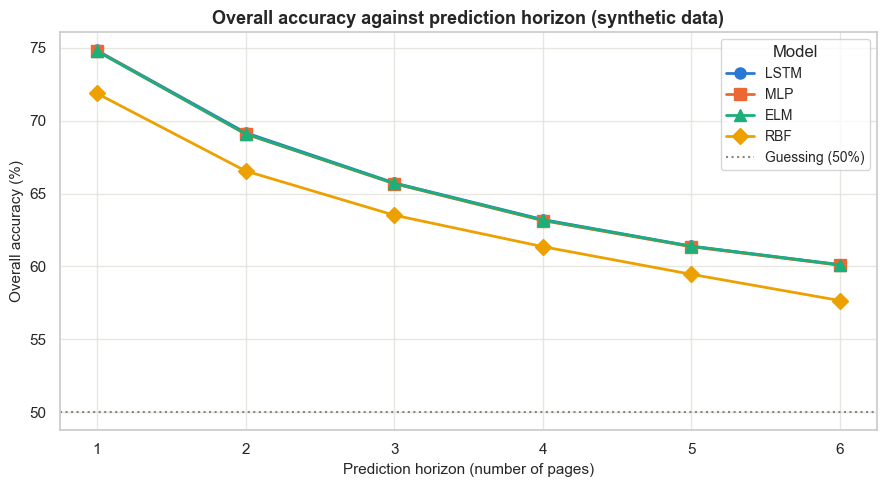

model,ELM,LSTM,MLP,RBF
h,,,,
1,74.8,74.8,74.8,71.9
2,69.1,69.2,69.1,66.6
3,65.7,65.7,65.7,63.5
4,63.2,63.2,63.1,61.4
5,61.4,61.4,61.3,59.5
6,60.1,60.1,60.1,57.7


In [8]:
acc = res.groupby(["model", "h"])["accuracy"].mean().unstack(0) * 100
fig, ax = plt.subplots()
for colour, marker, name in zip(COLOURS, ["o", "s", "^", "D"], ["LSTM", "MLP", "ELM", "RBF"]):
    ax.plot(acc.index, acc[name], marker=marker, color=colour, linewidth=2, markersize=8, label=name)
ax.axhline(50, color="#898781", linestyle=":", label="Guessing (50%)")
ax.set_title("Overall accuracy against prediction horizon (synthetic data)")
ax.set_xlabel("Prediction horizon (number of pages)")
ax.set_ylabel("Overall accuracy (%)")
ax.legend(title="Model")
plt.tight_layout()
plt.show()
show_table(acc, "Mean accuracy % per horizon", digits=1)

Accuracy falls at every step, from 74.8% at horizon 1 to 60.1% at horizon 6. The paper shows the same falling pattern. The LSTM, MLP and ELM lines sit almost on top of each other. RBF is about 2 to 3 points lower.

## 8. LSTM against the other models
A paired t-test compares two models one seed at a time on the same data. When we call a difference significant, we mean it is unlikely to be just chance. Two stars mean p is below 0.01, one star means p is below 0.05, and N.S. means not significant. With only 5 seeds, these tests are not very strong.

We expected a difference from the paper. Our generator is a first-order Markov chain, so the next page and the exit decision depend only on the current page. Earlier pages add no information, so the LSTM has little to gain over the flattened models. Finding no LSTM advantage would come from how we built the data, and it would not contradict the paper.

In [9]:
rows = []
for h in HORIZONS:
    part = res[res["h"] == h].sort_values("repeat")
    out = {"Horizon": h}
    lstm_acc = part[part["model"] == "LSTM"]["accuracy"].values
    for other in ["MLP", "ELM", "RBF"]:
        out[f"LSTM vs {other}"] = paired_test(lstm_acc, part[part["model"] == other]["accuracy"].values)[1]
    rows.append(out)
pd.DataFrame(rows).set_index("Horizon")

,LSTM vs MLP,LSTM vs ELM,LSTM vs RBF
Horizon,,,
1,N.S.,N.S.,**
2,*,*,**
3,N.S.,N.S.,**
4,*,N.S.,**
5,N.S.,N.S.,**
6,N.S.,N.S.,**


The LSTM beats RBF at every horizon (p below 0.01), by 1.9 to 3.0 points. Against MLP and ELM it is at most 0.09 points ahead, marked significant only at horizon 2 (both) and horizon 4 (MLP). A gap that small has no practical meaning. The paper finds the LSTM significantly better at every horizon, but our data gives it little to gain.

## 9. Figure 2 (right): LSTM against threshold
A threshold is the score above which we say a visitor will leave. The left panel shows the true positive rate (TPR), the share of real leavers the model flags. The right panel shows precision, the share of flagged visitors who really leave. Look at whether each line rises or falls as the threshold goes up.

A note on the paper's figure: its curves rise with the threshold, with the highest "true positive rate" at 0.90. A true TPR should not behave this way, because a higher threshold can only remove positive predictions. So the paper's rising curves appear to show precision. This is our reading, and the paper does not say so. We show both and compare the paper's curves with our right panel.

Precision is undefined when nobody is flagged. Those points are left out and counted in a note, not drawn as 0. Each point averages only the seeds that flagged someone.

What to expect: a simple lookup of page type and short stay did about as well in a side check, so we do not expect any model to do much better on this data. The generator's numbers are our own choice, so similarity to the paper's accuracy comes from those choices and is not evidence of replication.

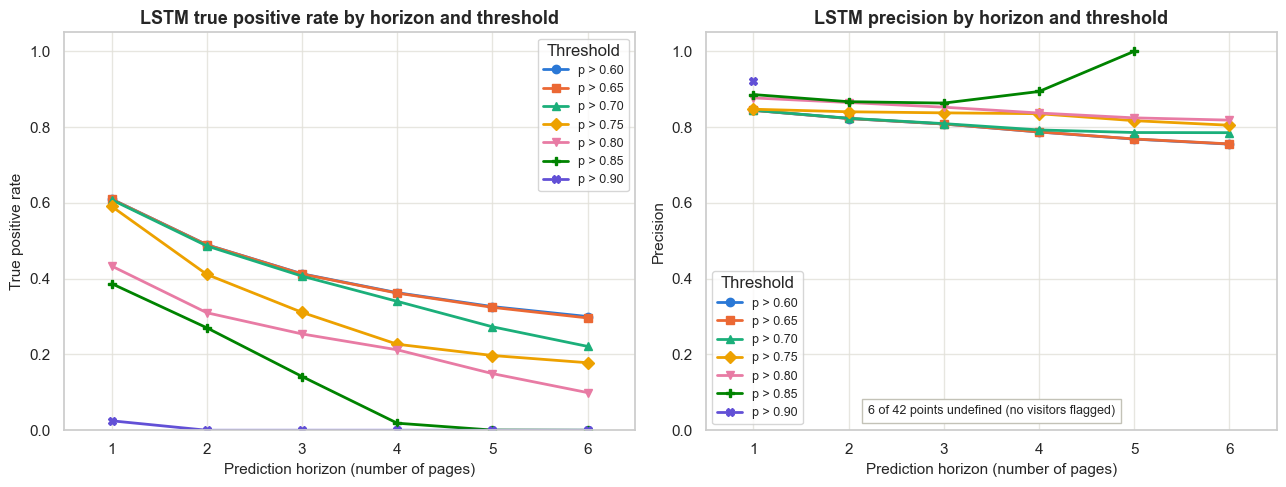

In [10]:
tpr = by_threshold.groupby(["threshold", "horizon"])["tpr"].mean().unstack(0)
precision = by_threshold.groupby(["threshold", "horizon"])["precision"].mean().unstack(0)
markers = ["o", "s", "^", "D", "v", "P", "X"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, table, label in zip(axes, [tpr, precision], ["True positive rate", "Precision"]):
    for colour, marker, t in zip(COLOURS, markers, THRESHOLDS):
        ax.plot(table.index, table[t], marker=marker, color=colour, linewidth=2, label=f"p > {t:.2f}")
    ax.set_title(f"LSTM {label.lower()} by horizon and threshold")
    ax.set_xlabel("Prediction horizon (number of pages)")
    ax.set_ylabel(label)
    ax.set_xticks(HORIZONS)
    ax.set_xlim(0.5, 6.5)
    ax.set_ylim(0, 1.05)
    ax.legend(title="Threshold", fontsize=9)

# Precision needs at least one flagged visitor. Without one it is undefined, not zero.
n_undefined = precision.isna().sum().sum()
note_box = {"facecolor": "white", "edgecolor": "#c3c2b7"}
if n_undefined == precision.size:
    axes[1].get_legend().remove()
    axes[1].text(0.5, 0.5, "Precision undefined at every point:\nthe LSTM flagged no visitors at these thresholds",
                 transform=axes[1].transAxes, ha="center", va="center", bbox=note_box)
elif n_undefined > 0:
    axes[1].text(0.5, 0.04, f"{n_undefined} of {precision.size} points undefined (no visitors flagged)",
                 transform=axes[1].transAxes, ha="center", fontsize=9, bbox=note_box)
plt.tight_layout()
plt.show()

As the threshold rises, TPR falls and precision rises. At horizon 1, going from 0.60 to 0.90 lowers TPR from 0.61 to 0.02 and raises precision from 0.84 to 0.92. So our precision has the same rising shape as the paper's curves. At 0.90, only one seed in five flags anyone at horizon 1, and none does at longer horizons. The note on the plot says 6 of the 42 points are undefined.

## 10. The paper's key numbers
We cannot compare these with the paper, because our data is synthetic. We list them only to show what each study reports.

In [ ]:
def best_text(table):
    if table.isna().all().all():
        return "undefined (no visitors flagged)"
    if table.max().max() == 0:
        return "0.00 (no visitors flagged)"
    h, t = table.stack().idxmax()
    return f"{table.loc[h, t]:.2f} (h={h}, t={t:.2f})"

key = pd.DataFrame({
    "Paper": ["74.3", "0.94 (h=2, t=0.90)", "not reported"],
    "Ours (synthetic)": [f"{acc.loc[1, 'LSTM']:.1f}",
                         best_text(tpr),
                         best_text(precision)],
}, index=["LSTM accuracy % at horizon 1", "Maximum true positive rate", "Maximum precision"])
key

,Paper,Ours (synthetic)
LSTM accuracy % at horizon 1,74.3,74.8
Maximum true positive rate,"0.94 (h=2, t=0.90)","0.61 (h=1, t=0.60)"
Maximum precision,not reported,"1.00 (h=5, t=0.85)"


The closeness of 74.8% to the paper's 74.3% is not a real match, because we chose the generator's numbers. Our maximum TPR is at the lowest threshold, as it must be for a true TPR. The maximum precision of 1.00 is not reliable, because it comes from very few windows.

## 11. Putting both modules together
This follows paper Algorithm 1 and Figure 1. After each page view, the abandonment module gives a score s1. Only if s1 is above a threshold a1 do we ask the purchase module for a score s2. We offer content only if s2 is also above a threshold a2, which is 0.5 by default. There are four outcomes.

If the visitor is leaving and interested (s1 high, s2 high), we offer content. This is the visitor the system is built for.

If the visitor is leaving and not interested (s1 high, s2 low), we make no offer, since a discount would probably be wasted.

If the visitor is staying and interested (s1 low, s2 high), we make no offer, since this visitor may buy anyway.

If the visitor is staying and not interested (s1 low, s2 low), we make no offer.

In [ ]:
def should_offer_content(s1, s2, a1, a2=0.5):
    # True only when the visitor is likely to leave AND has purchase intention.
    return s1 > a1 and s2 > a2

# ILLUSTRATION ONLY: made-up scores, not model outputs. The two modules use different datasets here.
A1 = 0.70
examples = pd.DataFrame({
    "Example": ["Leaving, interested", "Leaving, not interested", "Staying, interested", "Staying, not interested"],
    "s1 (abandonment)": [0.85, 0.85, 0.30, 0.30],
    "s2 (purchase)": [0.80, 0.20, 0.80, 0.20],
})
examples["Offer content?"] = [should_offer_content(s1, s2, A1) for s1, s2 in zip(examples["s1 (abandonment)"], examples["s2 (purchase)"])]
show_table(examples.set_index("Example"), f"Illustration with made-up scores (a1 = {A1}, a2 = 0.5)")

,s1 (abandonment),s2 (purchase),Offer content?
Example,,,
"Leaving, interested",0.85,0.80,True
"Leaving, not interested",0.85,0.20,False
"Staying, interested",0.30,0.80,False
"Staying, not interested",0.30,0.20,False


This table is only an illustration, using made-up scores and not model outputs. Only the first row gets an offer. In our project the two modules use different data, so we cannot test the combined system for real.

## 12. Results at a glance
These use 5 seeds on synthetic data. The paper column is not comparable, because the data is different.

| Horizon | LSTM accuracy % (ours, synthetic) | Best other model % (ours, synthetic) | RBF % (ours, synthetic) |
|---|---|---|---|
| 1 | 74.8 | 74.8 (MLP, ELM) | 71.9 |
| 2 | 69.2 | 69.1 (MLP, ELM) | 66.6 |
| 3 | 65.7 | 65.7 (MLP, ELM) | 63.5 |
| 4 | 63.2 | 63.2 (ELM) | 61.4 |
| 5 | 61.4 | 61.4 (ELM) | 59.5 |
| 6 | 60.1 | 60.1 (MLP, ELM) | 57.7 |

The method runs correctly and behaves as expected: accuracy falls as the horizon grows. The LSTM ties with the simple MLP and ELM, and that is what we expected, because our data depends only on the current page. Raising the threshold lowers TPR and raises precision, which supports our reading of the paper's Figure 2. None of these numbers can show that the paper's LSTM result holds on real data.

## 13. Key takeaways
(We ran 5 seeds on synthetic data).

1. The LSTM reaches 74.8% at horizon 1 and 60.1% at horizon 6. The paper reports 74.3% at horizon 1, and its figure shows about 59.5% at horizon 6, but the closeness comes from our choice of generator numbers. Accuracy falls at every step, the same pattern as in the paper.

2. The LSTM beats RBF at every horizon (p below 0.01, by 1.9 to 3.0 points). Against MLP and ELM it is at most 0.09 points ahead, with significance only at horizon 2 (both) and horizon 4 (MLP). A gap that small has no practical meaning. The paper finds the LSTM significantly better at every horizon, while our data gives it little to gain.

3. At horizon 1, raising the threshold from 0.60 to 0.90 lowers TPR  and raises precision. Precision rises as the paper's curves do, which supports our reading that its figure appears to show precision.

*For a shop, a threshold of 0.60 to 0.75 flags most of the visitors the model can catch at horizon 1 (TPR about 0.6, precision about 0.85), while 0.90 flags almost nobody. A real shop would need to repeat this on its own data.*